# Predicting Student Performance using Machine Learning
**Course:** Predictive Analytics (CA2)  |  **Name:** Amit kumar  **Reg.No:** 12408735  **Roll.No:** 15

## 1. Problem Statement
Can we predict whether a student will be a **Good Performer** (exam score ≥ 68) or **Needs Improvement** using study habits, attendance, family and school factors?

**Objectives:** (1) clean the data, (2) explore it with charts and statistics, (3) build 5 models – **Logistic Regression, KNN, Naive Bayes, Decision Tree, SVM** – and (4) compare them using train accuracy, test accuracy, precision, recall and F1-score.

## 2. Dataset
`StudentPerformanceFactors.csv` – 6,607 students, 20 columns (study hours, attendance, parental involvement, motivation, sleep, previous scores, etc.). Target: `Exam_Score`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
sns.set_theme(style='whitegrid')
os.makedirs('figs', exist_ok=True)
R = {}   # stores numbers for the report

## 3. Load the Data

In [2]:
# find the dataset (works from the notebook folder or the project root)
DATA = next(p for p in ['StudentPerformanceFactors.csv', '../02_Dataset/StudentPerformanceFactors.csv', '02_Dataset/StudentPerformanceFactors.csv'] if os.path.exists(p))
df = pd.read_csv(DATA)
R['shape'] = list(df.shape)
print(df.shape)
df.head()

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## 4. Data Cleaning

In [3]:
# 1) Missing values
miss = df.isnull().sum(); miss = miss[miss > 0]
R['missing'] = {k:int(v) for k,v in miss.items()}
print('Missing values:\n', miss)

# Fill missing text values with the most common value (mode)
for c in miss.index:
    df[c] = df[c].fillna(df[c].mode()[0])

# 2) Duplicates
R['duplicates'] = int(df.duplicated().sum())
print('\nDuplicate rows:', R['duplicates'])

# 3) Impossible values: exam score cannot be more than 100
R['bad_scores'] = int((df['Exam_Score'] > 100).sum())
df['Exam_Score'] = df['Exam_Score'].clip(upper=100)
print('Scores above 100 fixed:', R['bad_scores'])
print('Missing values left:', int(df.isnull().sum().sum()))

Missing values:
 Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate rows: 0
Scores above 100 fixed: 1
Missing values left: 0


**Outlier check (IQR rule):**

In [4]:
# Outliers by the IQR rule (Q1 - 1.5*IQR, Q3 + 1.5*IQR)
num_cols = df.select_dtypes(include='number').columns.tolist()
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, round(lo, 2), round(hi, 2), n_out, round(n_out/len(df)*100, 2)])
R['outliers'] = rows
pd.DataFrame(rows, columns=['Feature','Lower fence','Upper fence','Outliers','Outlier %'])

,Feature,Lower fence,Upper fence,Outliers,Outlier %
0,Hours_Studied,4.0,36.0,43,0.65
1,Attendance,40.0,120.0,0,0.00
2,Sleep_Hours,3.0,11.0,0,0.00
3,Previous_Scores,25.5,125.5,0,0.00
4,Tutoring_Sessions,-0.5,3.5,430,6.51
5,Physical_Activity,-1.0,7.0,0,0.00
6,Exam_Score,59.0,75.0,104,1.57


## 5. Visualization

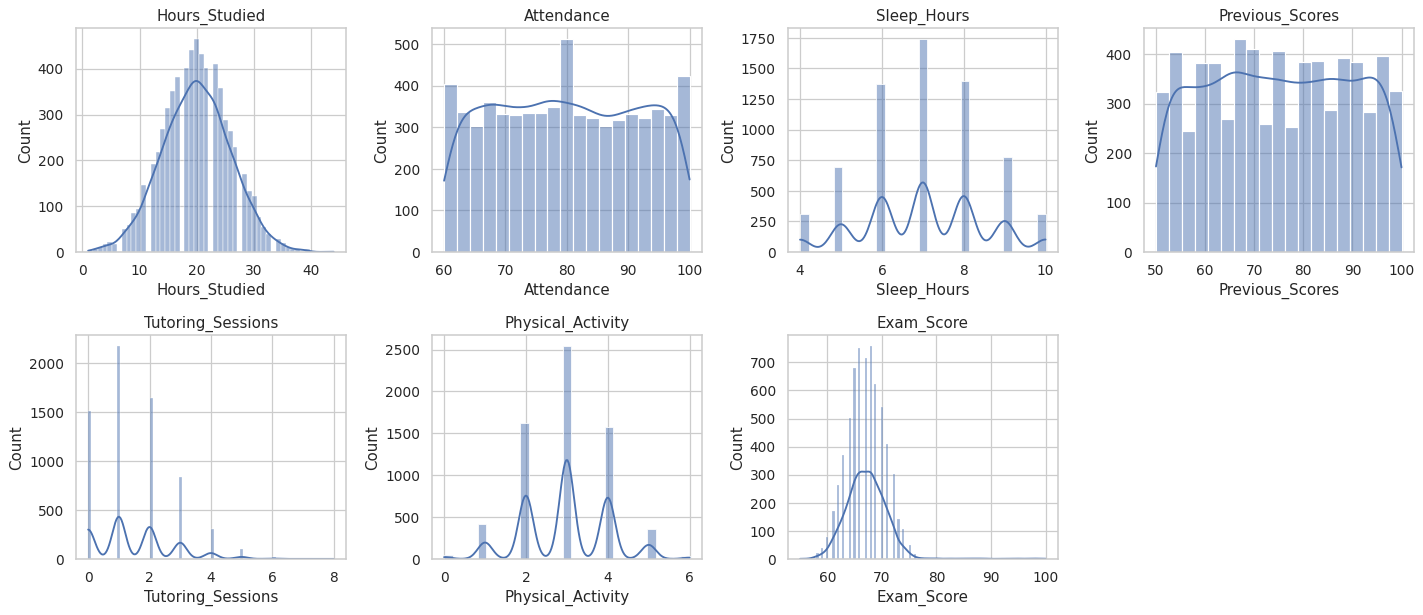

In [5]:
num_cols = df.select_dtypes(include='number').columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax); ax.set_title(c)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig('figs/01_hist.png', dpi=100, bbox_inches='tight'); plt.show()

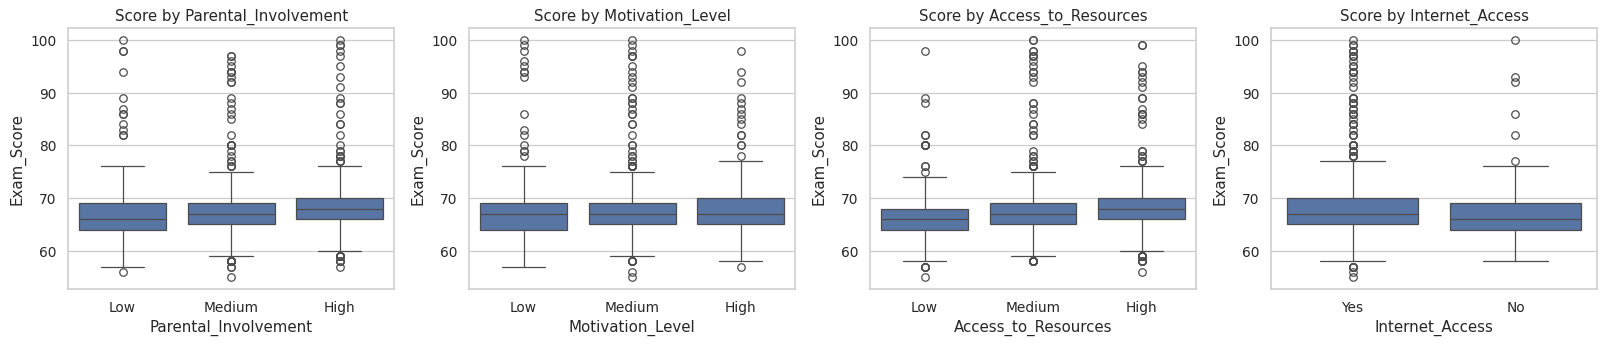

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['Parental_Involvement', 'Motivation_Level', 'Access_to_Resources', 'Internet_Access']):
    order = ['Low','Medium','High'] if c != 'Internet_Access' else None
    sns.boxplot(x=c, y='Exam_Score', data=df, order=order, ax=ax); ax.set_title('Score by ' + c)
plt.tight_layout(); plt.savefig('figs/02_box.png', dpi=100, bbox_inches='tight'); plt.show()

**Counts of the categorical columns:**

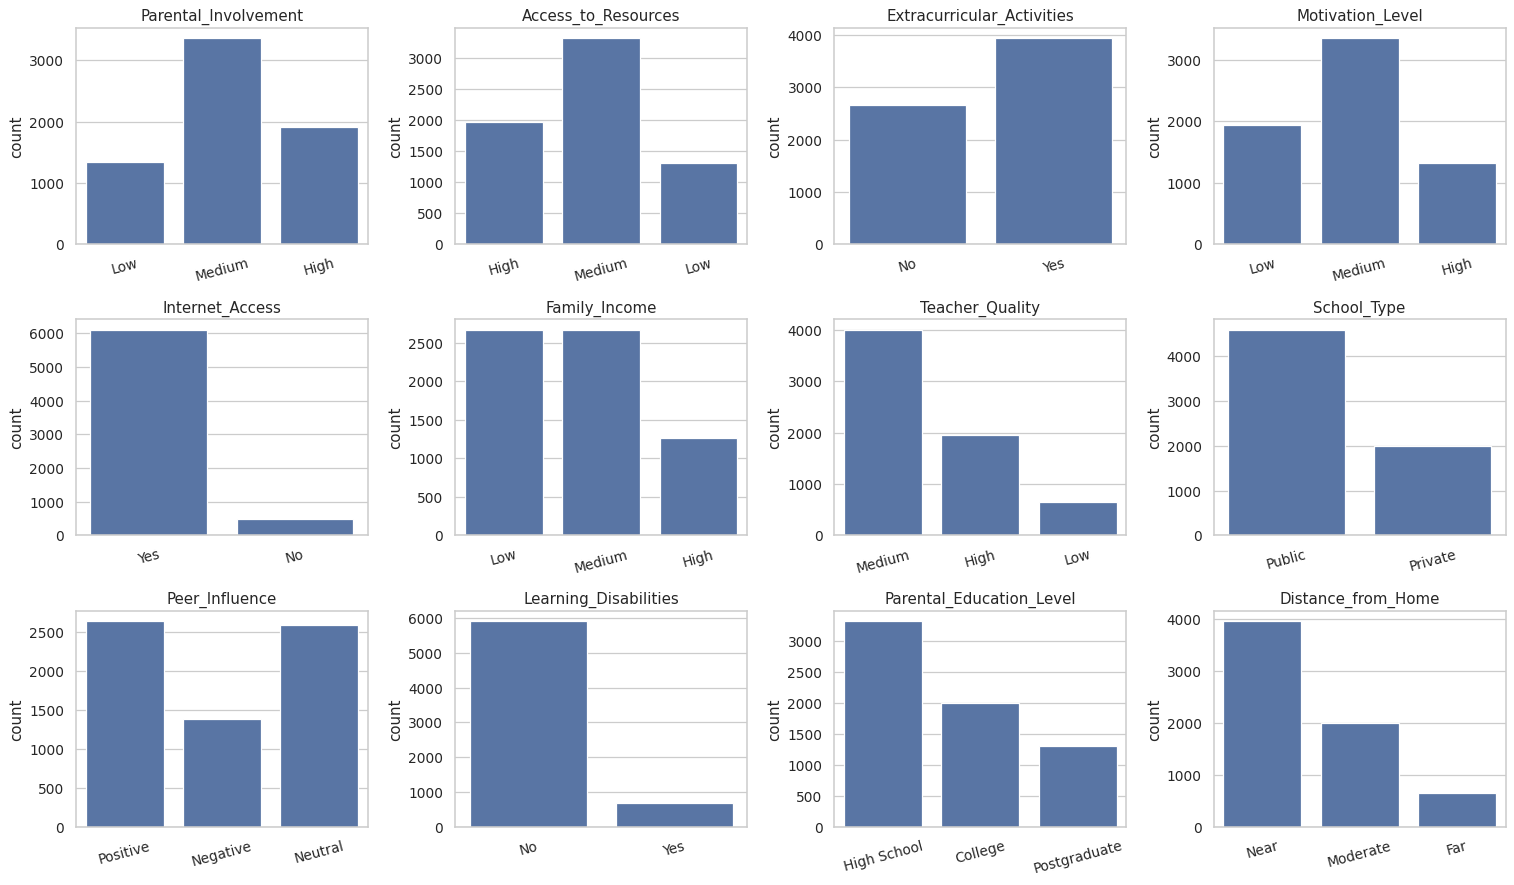

In [7]:
cat_cols = [c for c in df.select_dtypes(exclude='number').columns]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(x=c, data=df, ax=ax); ax.set_title(c); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=15)
for ax in axes.ravel()[len(cat_cols):]: ax.axis('off')
plt.tight_layout(); plt.savefig('figs/10_counts.png', dpi=100, bbox_inches='tight'); plt.show()

## 6. EDA and Statistical Analysis

In [8]:
d = df.describe().T.round(2)
d['skew'] = df[num_cols].skew().round(2)
d

,count,mean,std,min,25%,50%,75%,max,skew
Hours_Studied,6607.0,19.98,5.99,1.0,16.0,20.0,24.0,44.0,0.01
Attendance,6607.0,79.98,11.55,60.0,70.0,80.0,90.0,100.0,0.01
Sleep_Hours,6607.0,7.03,1.47,4.0,6.0,7.0,8.0,10.0,-0.02
Previous_Scores,6607.0,75.07,14.40,50.0,63.0,75.0,88.0,100.0,-0.00
Tutoring_Sessions,6607.0,1.49,1.23,0.0,1.0,1.0,2.0,8.0,0.82
Physical_Activity,6607.0,2.97,1.03,0.0,2.0,3.0,4.0,6.0,-0.03
Exam_Score,6607.0,67.24,3.89,55.0,65.0,67.0,69.0,100.0,1.64


Performance
0    3599
1    3008
Name: count, dtype: int64


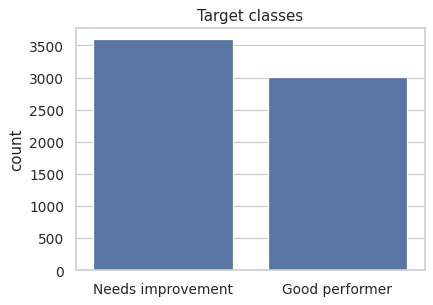

In [9]:
# Target: Good performer (1) if score >= 68, else 0
df['Performance'] = (df['Exam_Score'] >= 68).astype(int)
R['class_counts'] = {'good': int((df.Performance==1).sum()), 'needs': int((df.Performance==0).sum())}
print(df['Performance'].value_counts())
plt.figure(figsize=(5,3.5)); sns.countplot(x=df['Performance'].map({0:'Needs improvement',1:'Good performer'}))
plt.xlabel(''); plt.title('Target classes'); plt.savefig('figs/03_target.png', dpi=100, bbox_inches='tight'); plt.show()

In [10]:
# Convert text columns to numbers (needed by ML models)
enc = df.copy()
lvl = {'Low':0, 'Medium':1, 'High':2}
for c in ['Parental_Involvement','Access_to_Resources','Motivation_Level','Family_Income','Teacher_Quality']:
    enc[c] = enc[c].map(lvl)
enc['Distance_from_Home'] = enc['Distance_from_Home'].map({'Near':0, 'Moderate':1, 'Far':2})
enc['Parental_Education_Level'] = enc['Parental_Education_Level'].map({'High School':0, 'College':1, 'Postgraduate':2})
enc['Peer_Influence'] = enc['Peer_Influence'].map({'Negative':0, 'Neutral':1, 'Positive':2})
for c in ['Extracurricular_Activities','Internet_Access','Learning_Disabilities']:
    enc[c] = (enc[c] == 'Yes').astype(int)
enc['School_Type'] = (enc['School_Type'] == 'Private').astype(int)
enc['Gender'] = (enc['Gender'] == 'Male').astype(int)
enc.head(3)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Performance
0,23,84,0,2,0,7,73,0,1,0,0,1,0,2,3,0,0,0,1,67,0
1,19,64,0,1,0,8,59,0,1,2,1,1,0,0,4,0,1,1,0,61,0
2,24,98,1,1,1,7,91,1,1,2,1,1,0,1,4,0,2,0,1,74,1


Attendance              0.581
Hours_Studied           0.446
Previous_Scores         0.175
Access_to_Resources     0.170
Parental_Involvement    0.157
Name: Exam_Score, dtype: float64


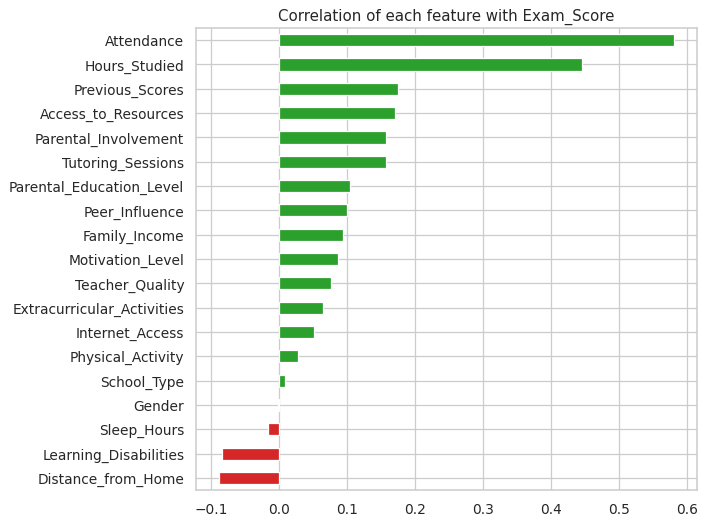

In [11]:
# Correlation with Exam_Score
corr = enc.drop(columns='Performance').corr()['Exam_Score'].drop('Exam_Score').sort_values()
R['corr'] = corr.round(3).to_dict()
plt.figure(figsize=(8,6)); corr.plot(kind='barh', color=['#d62728' if v<0 else '#2ca02c' for v in corr])
plt.title('Correlation of each feature with Exam_Score'); plt.tight_layout()
plt.savefig('figs/04_corr.png', dpi=100, bbox_inches='tight'); plt.show()
print(corr.sort_values(ascending=False).head(5).round(3))

**Correlation heat-map (all features):**

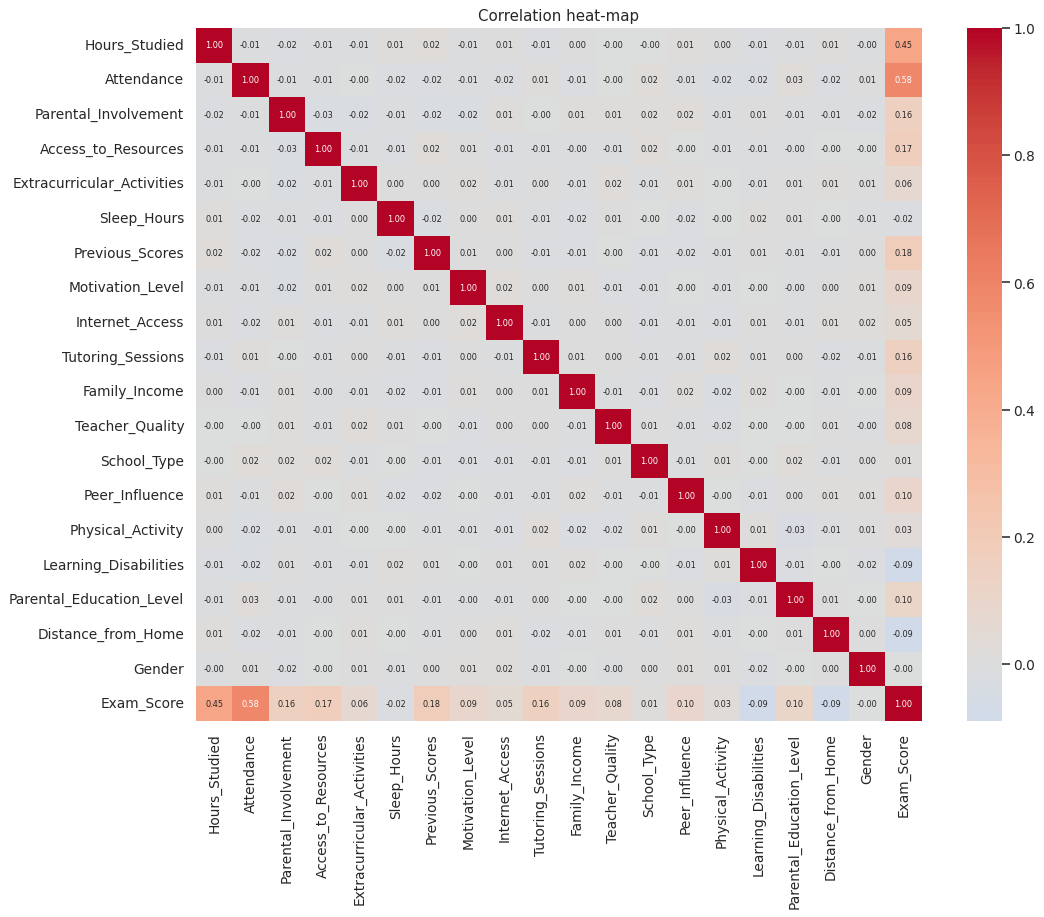

In [12]:
plt.figure(figsize=(13, 10)); sns.heatmap(enc.drop(columns='Performance').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size':6.5})
plt.title('Correlation heat-map'); plt.savefig('figs/11_heatmap.png', dpi=100, bbox_inches='tight'); plt.show()

**Relationship plots and group-wise average scores:**

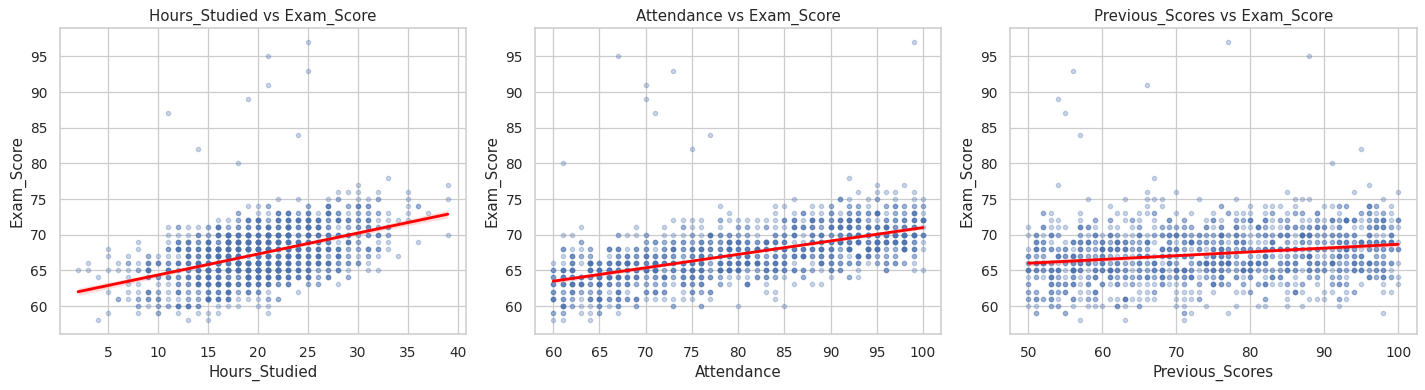

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, ['Hours_Studied','Attendance','Previous_Scores']):
    sns.regplot(x=c, y='Exam_Score', data=df.sample(1500, random_state=1), ax=a, scatter_kws={'alpha':.3, 's':12}, line_kws={'color':'red'}); a.set_title(c + ' vs Exam_Score')
plt.tight_layout(); plt.savefig('figs/12_scatter.png', dpi=100, bbox_inches='tight'); plt.show()

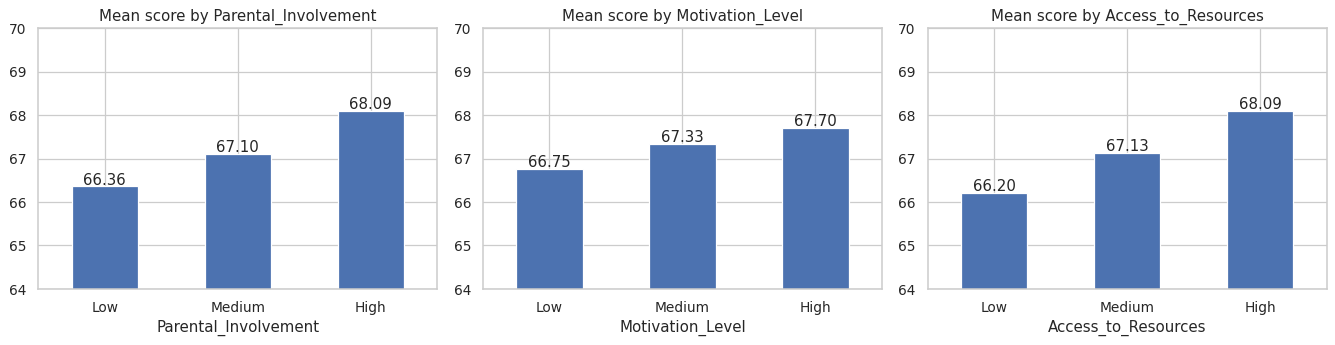

In [14]:
gm = {c: df.groupby(c)['Exam_Score'].mean().round(2).to_dict() for c in ['Parental_Involvement','Motivation_Level','Access_to_Resources','Family_Income','Internet_Access','Learning_Disabilities','School_Type','Gender']}
R['group_means'] = gm
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ['Parental_Involvement','Motivation_Level','Access_to_Resources']):
    m = df.groupby(c)['Exam_Score'].mean().reindex(['Low','Medium','High']); m.plot(kind='bar', ax=a, rot=0); a.set_ylim(64, 70); a.set_title('Mean score by ' + c)
    for i, v in enumerate(m): a.text(i, v + .05, f'{v:.2f}', ha='center')
plt.tight_layout(); plt.savefig('figs/13_groupmeans.png', dpi=100, bbox_inches='tight'); plt.show()

In [15]:
# Statistical tests (alpha = 0.05)
rows = []
r, p = stats.pearsonr(df.Attendance, df.Exam_Score);   rows.append(['Pearson: Attendance vs Score', f'r={r:.2f}', p])
r, p = stats.pearsonr(df.Hours_Studied, df.Exam_Score); rows.append(['Pearson: Hours_Studied vs Score', f'r={r:.2f}', p])
t, p = stats.ttest_ind(df[df.Internet_Access=='Yes'].Exam_Score, df[df.Internet_Access=='No'].Exam_Score)
rows.append(['t-test: Internet access Yes vs No', f't={t:.2f}', p])
t, p = stats.ttest_ind(df[df.School_Type=='Public'].Exam_Score, df[df.School_Type=='Private'].Exam_Score)
rows.append(['t-test: Public vs Private school', f't={t:.2f}', p])
f, p = stats.f_oneway(*[g.Exam_Score for _, g in df.groupby('Parental_Involvement')])
rows.append(['ANOVA: Parental involvement', f'F={f:.1f}', p])
chi, p, _, _ = stats.chi2_contingency(pd.crosstab(df.Motivation_Level, df.Performance))
rows.append(['Chi-square: Motivation vs Performance', f'chi2={chi:.1f}', p])
tests = pd.DataFrame(rows, columns=['Test','Statistic','p-value'])
tests['Result'] = np.where(tests['p-value'] < 0.05, 'Significant', 'Not significant')
tests['p-value'] = tests['p-value'].map(lambda v: f'{v:.2e}')
R['tests'] = tests.values.tolist()
tests

,Test,Statistic,p-value,Result
0,Pearson: Attendance vs Score,r=0.58,0.00e+00,Significant
1,Pearson: Hours_Studied vs Score,r=0.45,8.82e-320,Significant
2,t-test: Internet access Yes vs No,t=4.20,2.69e-05,Significant
3,t-test: Public vs Private school,t=-0.72,4.71e-01,Not significant
4,ANOVA: Parental involvement,F=84.6,5.23e-37,Significant
5,Chi-square: Motivation vs Performance,chi2=30.6,2.28e-07,Significant


**Insight:** Attendance and hours studied matter most. Parental involvement, motivation and internet access also matter. School type does not.

## 7. Model Building
**Steps:** select features → split data 80% train / 20% test → scale features → train 5 models → compare.

In [16]:
FEATURES = [c for c in enc.columns if c not in ['Exam_Score', 'Performance']]   # score is NOT used as a feature
X, y = enc[FEATURES], enc['Performance']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
R['split'] = [len(X_train), len(X_test)]

Train: (5285, 19)  Test: (1322, 19)


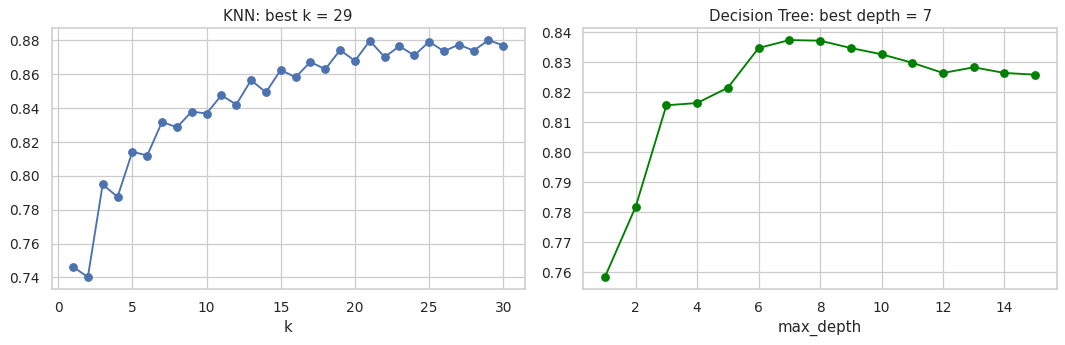

In [17]:
# Choose k for KNN and depth for Decision Tree using cross-validation on TRAIN data only
ks = range(1, 31)
k_sc = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), X_train, y_train, cv=5).mean() for k in ks]
best_k = list(ks)[int(np.argmax(k_sc))]
ds = range(1, 16)
d_sc = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), X_train, y_train, cv=5).mean() for d in ds]
best_d = list(ds)[int(np.argmax(d_sc))]
R['best_k'], R['best_depth'] = int(best_k), int(best_d)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, k_sc, marker='o'); ax[0].set_title(f'KNN: best k = {best_k}'); ax[0].set_xlabel('k')
ax[1].plot(ds, d_sc, marker='o', color='green'); ax[1].set_title(f'Decision Tree: best depth = {best_d}'); ax[1].set_xlabel('max_depth')
plt.tight_layout(); plt.savefig('figs/05_tuning.png', dpi=100, bbox_inches='tight'); plt.show()

In [18]:
models = {
    'Logistic Regression':    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'KNN':                    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
    'Naive Bayes':            make_pipeline(StandardScaler(), GaussianNB()),
    'Decision Tree':          DecisionTreeClassifier(max_depth=best_d, random_state=42),
    'SVM':                    make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=42)),
}
rows, preds, probs = [], {}, {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    preds[name], probs[name] = p_te, m.predict_proba(X_test)[:, 1]
    rows.append([name, accuracy_score(y_train, p_tr), accuracy_score(y_test, p_te),
                 precision_score(y_test, p_te), recall_score(y_test, p_te), f1_score(y_test, p_te),
                 roc_auc_score(y_test, probs[name])])
result = pd.DataFrame(rows, columns=['Model','Train Accuracy','Test Accuracy','Precision','Recall','F1-Score','ROC-AUC']).set_index('Model').round(4)
result = result.sort_values('Test Accuracy', ascending=False)
R['results'] = result.reset_index().values.tolist()
best = result.index[0]; R['best'] = best
print('Best model:', best)
result

Best model: Logistic Regression


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,,
Logistic Regression,0.9815,0.9841,0.9770,0.9884,0.9827,0.9952
SVM,0.9881,0.9607,0.9568,0.9568,0.9568,0.9922
KNN,0.9010,0.8850,0.9213,0.8173,0.8662,0.9575
Naive Bayes,0.8819,0.8654,0.8498,0.8555,0.8526,0.9443
Decision Tree,0.8935,0.8366,0.8339,0.8007,0.8169,0.8892


## 8. Model Comparison

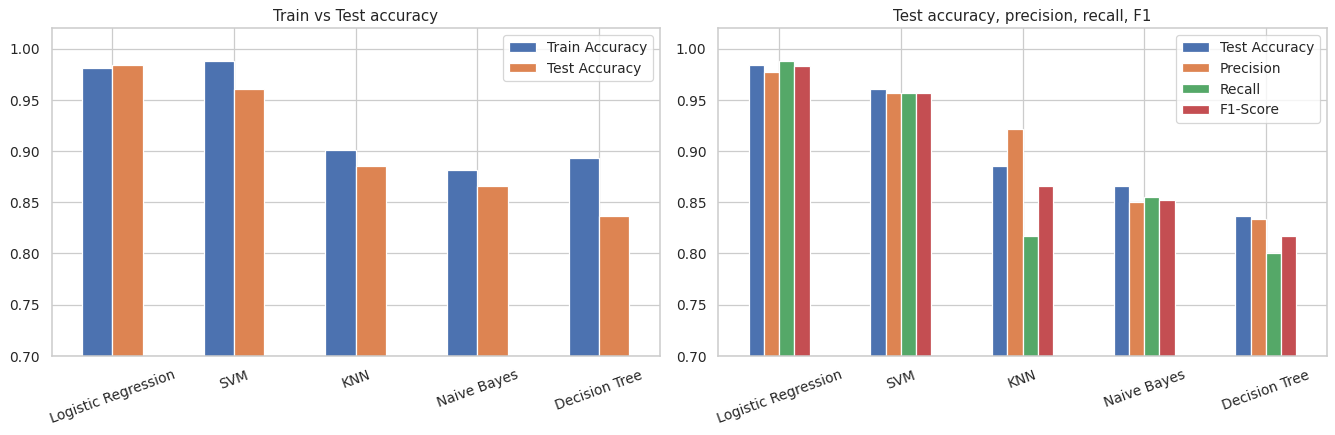

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
result[['Train Accuracy','Test Accuracy']].plot(kind='bar', ax=ax[0], rot=20); ax[0].set_ylim(.7, 1.02); ax[0].set_title('Train vs Test accuracy'); ax[0].set_xlabel('')
result[['Test Accuracy','Precision','Recall','F1-Score']].plot(kind='bar', ax=ax[1], rot=20); ax[1].set_ylim(.7, 1.02); ax[1].set_title('Test accuracy, precision, recall, F1'); ax[1].set_xlabel('')
plt.tight_layout(); plt.savefig('figs/06_compare.png', dpi=100, bbox_inches='tight'); plt.show()

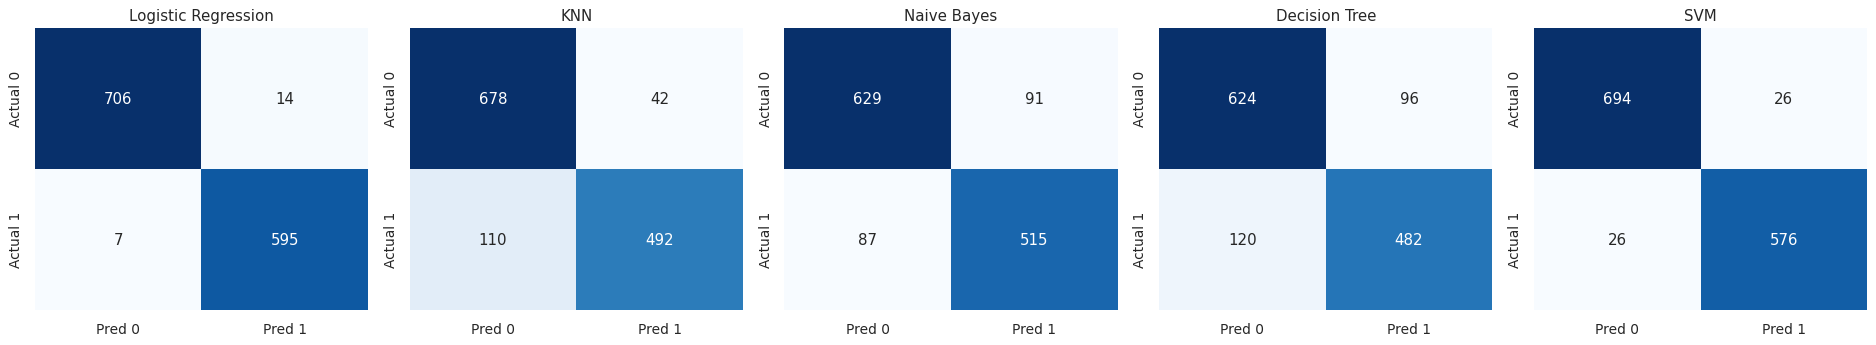

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4)); R['confusion'] = {}
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p); R['confusion'][name] = cm.tolist()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['Pred 0','Pred 1'], yticklabels=['Actual 0','Actual 1']); ax.set_title(name)
plt.tight_layout(); plt.savefig('figs/07_confusion.png', dpi=100, bbox_inches='tight'); plt.show()

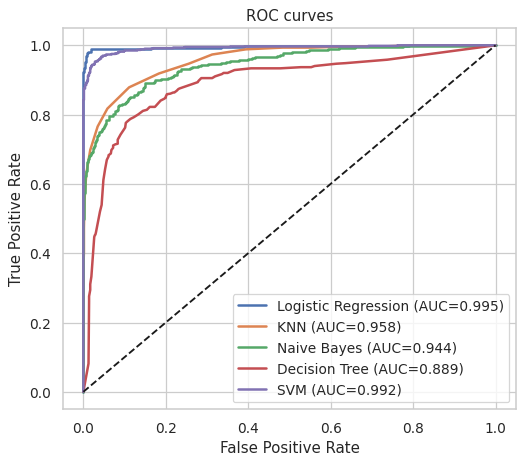

In [21]:
plt.figure(figsize=(6.5, 5.5))
for name, pr in probs.items():
    fpr, tpr, _ = roc_curve(y_test, pr); plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={roc_auc_score(y_test, pr):.3f})')
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC curves'); plt.legend(loc='lower right')
plt.savefig('figs/08_roc.png', dpi=100, bbox_inches='tight'); plt.show()

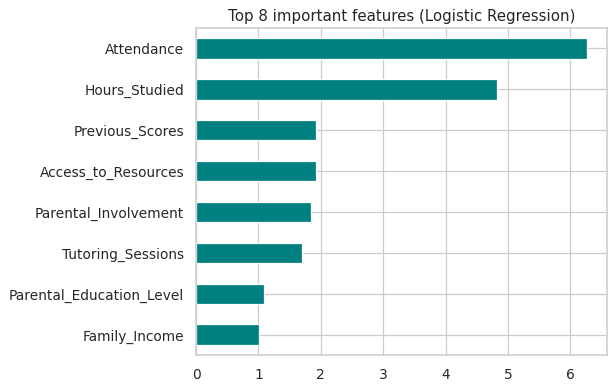

In [22]:
# Which features matter most? (Logistic Regression coefficients on scaled data)
coef = pd.Series(models['Logistic Regression'][-1].coef_[0], index=FEATURES).sort_values(key=abs, ascending=False).head(8)[::-1]
R['top_features'] = coef.round(3).to_dict()
plt.figure(figsize=(7, 4.5)); coef.plot(kind='barh', color='teal'); plt.title('Top 8 important features (Logistic Regression)')
plt.tight_layout(); plt.savefig('figs/09_importance.png', dpi=100, bbox_inches='tight'); plt.show()

## 9. Detailed Model-wise Analysis
A separate confusion matrix, classification report, log loss and cross-validation score for each of the five models, and a small decision tree (depth 3) to see the rules.

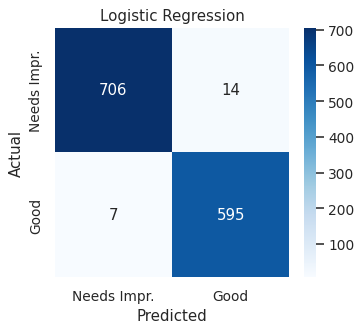

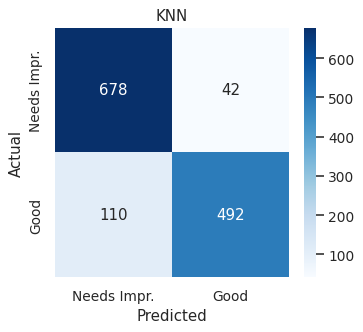

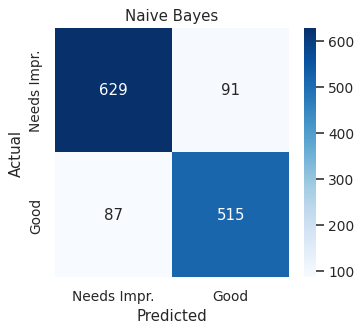

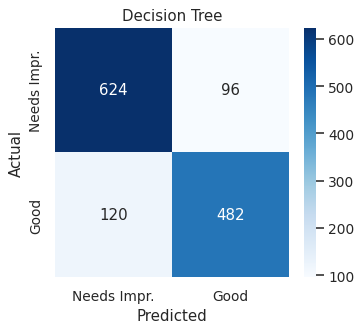

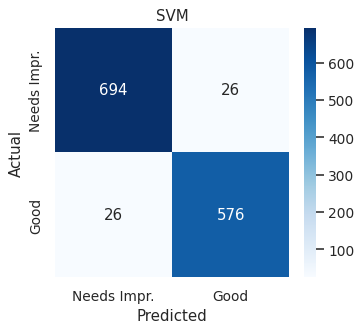

,Logistic Regression,KNN,Naive Bayes,Decision Tree,SVM
Log loss,0.1005,0.3985,0.3249,1.2563,0.1135
5-fold CV accuracy,0.9807,0.8800,0.8798,0.8375,0.9608


In [23]:
# Separate confusion matrix, classification report, log loss and CV accuracy for each model
from sklearn.metrics import log_loss, classification_report
R['extra'] = {}
for i, (name, m) in enumerate(models.items(), start=1):
    cm = confusion_matrix(y_test, preds[name])
    plt.figure(figsize=(4.2, 3.6)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Needs Impr.','Good'], yticklabels=['Needs Impr.','Good'])
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(name); plt.savefig(f'figs/14_cm_{i}.png', dpi=100, bbox_inches='tight'); plt.show()
    rep = classification_report(y_test, preds[name], output_dict=True)
    R['extra'][name] = {'logloss': float(log_loss(y_test, probs[name])), 'cv': float(cross_val_score(m, X_train, y_train, cv=5).mean()),
                        'c0': [rep['0']['precision'], rep['0']['recall'], rep['0']['f1-score'], int(rep['0']['support'])],
                        'c1': [rep['1']['precision'], rep['1']['recall'], rep['1']['f1-score'], int(rep['1']['support'])]}
pd.DataFrame({n: [v['logloss'], v['cv']] for n, v in R['extra'].items()}, index=['Log loss', '5-fold CV accuracy']).round(4)

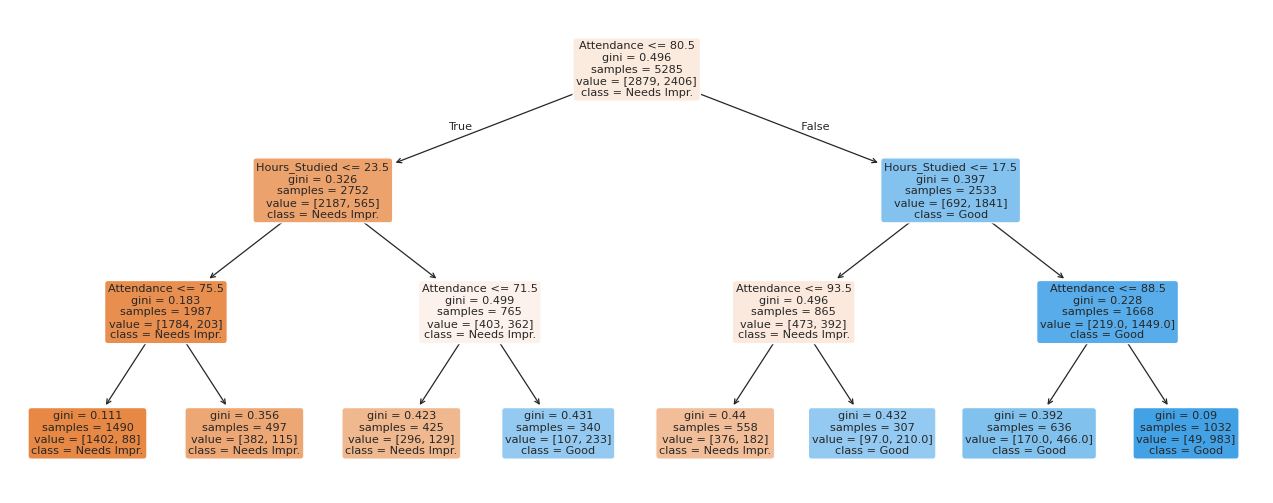

In [24]:
from sklearn.tree import plot_tree
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(18, 7)); plot_tree(tree3, feature_names=FEATURES, class_names=['Needs Impr.','Good'], filled=True, rounded=True, fontsize=9)
plt.savefig('figs/15_tree.png', dpi=100, bbox_inches='tight'); plt.show()

## 10. Conclusion
* **Logistic Regression** is the best model, followed by **SVM**. KNN, Naive Bayes and Decision Tree are lower.
* The Decision Tree has the biggest gap between train and test accuracy (overfitting).
* **Attendance** and **hours studied** are the most important factors; school type and gender do not matter.
* Schools can use this model to find students who need help early.

**Future scope:** Random Forest / XGBoost, hyper-parameter tuning, deployment as a web app.

In [25]:
json.dump(R, open('results.json', 'w'), indent=1, default=float)
print('Saved results.json')

Saved results.json
